In [ ]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
pd.set_option("display.max_columns", 50)

df = pd.read_csv("DatasetPMA.csv")
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


# **1. Pemeriksaan Data**

In [ ]:
print("Jumlah baris :", len(df))
print("Jumlah kolom :", len(df.columns))
print("\nNama kolom:")
print(df.columns.tolist())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("\nTipe data:")
display(df.dtypes.to_frame("dtype"))

Jumlah baris : 14640
Jumlah kolom : 15

Nama kolom:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

Missing values:


,missing
negativereason_gold,14608
airline_sentiment_gold,14600
tweet_coord,13621
negativereason,5462
user_timezone,4820
tweet_location,4733
negativereason_confidence,4118
airline,0
tweet_id,0
airline_sentiment,0



Tipe data:


,dtype
tweet_id,int64
airline_sentiment,object
airline_sentiment_confidence,float64
negativereason,object
negativereason_confidence,float64
airline,object
airline_sentiment_gold,object
name,object
negativereason_gold,object
retweet_count,int64


# **2. Feature Engineering**

Beberapa variabel numerik dibuat dari `text`, `tweet_created`, dan metadata. Dengan feature engineering ini, jumlah feature numerik menjadi lebih dari 15.

In [ ]:
data = df.copy()
data["text"] = data["text"].fillna("").astype(str)
data["tweet_created"] = pd.to_datetime(data["tweet_created"], errors="coerce")

data["text_length"] = data["text"].str.len()
data["word_count"] = data["text"].str.split().str.len()
data["unique_word_count"] = data["text"].apply(lambda x: len(set(x.lower().split())))
data["avg_word_length"] = data["text"].apply(lambda x: np.mean([len(w) for w in x.split()]) if x.split() else 0)
data["uppercase_count"] = data["text"].apply(lambda x: sum(c.isupper() for c in x))
data["lowercase_count"] = data["text"].apply(lambda x: sum(c.islower() for c in x))
data["digit_count"] = data["text"].apply(lambda x: sum(c.isdigit() for c in x))
data["punctuation_count"] = data["text"].apply(lambda x: sum(not c.isalnum() and not c.isspace() for c in x))
data["exclamation_count"] = data["text"].str.count("!")
data["question_count"] = data["text"].str.count(r"\?")
data["hashtag_count"] = data["text"].str.count("#")
data["mention_count"] = data["text"].str.count("@")
data["url_count"] = data["text"].str.lower().str.count("http")
data["dollar_count"] = data["text"].str.count(r"\$")
data["emoji_like_count"] = data["text"].apply(lambda x: sum(ord(c) > 10000 for c in x))

data["location_present"] = data["tweet_location"].fillna("").astype(str).str.strip().ne("").astype(int)
data["timezone_present"] = data["user_timezone"].fillna("").astype(str).str.strip().ne("").astype(int)
data["negative_reason_present"] = data["negativereason"].fillna("").astype(str).str.strip().ne("").astype(int)
data["coord_present"] = data["tweet_coord"].fillna("").astype(str).str.strip().ne("").astype(int)
data["name_present"] = data["name"].fillna("").astype(str).str.strip().ne("").astype(int)

data["year"] = data["tweet_created"].dt.year
data["month"] = data["tweet_created"].dt.month
data["day"] = data["tweet_created"].dt.day
data["hour"] = data["tweet_created"].dt.hour
data["dayofweek"] = data["tweet_created"].dt.dayofweek
data["is_weekend"] = data["dayofweek"].isin([5, 6]).astype(int)

target_map = {"negative": 0, "neutral": 1, "positive": 2}
data["sentiment_code"] = data["airline_sentiment"].map(target_map)

engineered_features = [
"airline_sentiment_confidence","negativereason_confidence","retweet_count",
"text_length","word_count","unique_word_count","avg_word_length","uppercase_count",
"lowercase_count","digit_count","punctuation_count","exclamation_count",
"question_count","hashtag_count","mention_count","url_count","dollar_count",
"emoji_like_count","location_present","timezone_present","negative_reason_present",
"coord_present","name_present","year","month","day","hour","dayofweek","is_weekend"]

print("Jumlah feature numerik:", len(engineered_features))
display(data[engineered_features].describe().T)


Jumlah feature numerik: 29


,count,mean,std,min,25%,50%,75%,max
airline_sentiment_confidence,14640.0,0.900169,0.162830,0.335000,0.692300,1.000000,1.000000,1.0
negativereason_confidence,10522.0,0.638298,0.330440,0.000000,0.360600,0.670600,1.000000,1.0
retweet_count,14640.0,0.082650,0.745778,0.000000,0.000000,0.000000,0.000000,44.0
text_length,14640.0,103.822063,36.277339,12.000000,77.000000,114.000000,136.000000,186.0
word_count,14640.0,17.653415,6.882259,2.000000,12.000000,19.000000,23.000000,36.0
unique_word_count,14640.0,16.748019,6.262772,2.000000,12.000000,18.000000,22.000000,32.0
avg_word_length,14640.0,5.160405,1.140310,3.153846,4.423077,4.913043,5.571429,18.5
uppercase_count,14640.0,5.917077,4.934667,0.000000,3.000000,5.000000,8.000000,103.0
lowercase_count,14640.0,74.713730,27.764848,5.000000,54.000000,82.000000,98.000000,136.0
digit_count,14640.0,1.285929,2.228021,0.000000,0.000000,0.000000,2.000000,33.0


# **3. Descriptive Statistics**

In [ ]:
print("Statistik deskriptif:")
display(data[engineered_features].describe().T)
print("\nDistribusi target:")
display(data["airline_sentiment"].value_counts().to_frame("jumlah"))
print("\nPersentase target:")
display((data["airline_sentiment"].value_counts(normalize=True)*100).round(2).to_frame("persentase"))
print("\nDistribusi maskapai:")
display(data["airline"].value_counts().to_frame("jumlah"))

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
airline_sentiment_confidence,14640.0,0.900169,0.162830,0.335000,0.692300,1.000000,1.000000,1.0
negativereason_confidence,10522.0,0.638298,0.330440,0.000000,0.360600,0.670600,1.000000,1.0
retweet_count,14640.0,0.082650,0.745778,0.000000,0.000000,0.000000,0.000000,44.0
text_length,14640.0,103.822063,36.277339,12.000000,77.000000,114.000000,136.000000,186.0
word_count,14640.0,17.653415,6.882259,2.000000,12.000000,19.000000,23.000000,36.0
unique_word_count,14640.0,16.748019,6.262772,2.000000,12.000000,18.000000,22.000000,32.0
avg_word_length,14640.0,5.160405,1.140310,3.153846,4.423077,4.913043,5.571429,18.5
uppercase_count,14640.0,5.917077,4.934667,0.000000,3.000000,5.000000,8.000000,103.0
lowercase_count,14640.0,74.713730,27.764848,5.000000,54.000000,82.000000,98.000000,136.0
digit_count,14640.0,1.285929,2.228021,0.000000,0.000000,0.000000,2.000000,33.0



Distribusi target:


,jumlah
airline_sentiment,
negative,9178
neutral,3099
positive,2363



Persentase target:


,persentase
airline_sentiment,
negative,62.69
neutral,21.17
positive,16.14



Distribusi maskapai:


,jumlah
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504


# **4. Visualisasi**

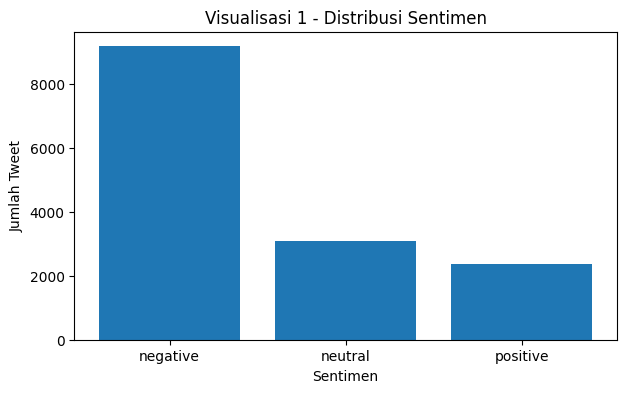

In [ ]:
order=["negative","neutral","positive"]
counts=data["airline_sentiment"].value_counts().reindex(order,fill_value=0)
plt.figure(figsize=(7,4))
plt.bar(counts.index, counts.values)
plt.title("Visualisasi 1 - Distribusi Sentimen")
plt.xlabel("Sentimen"); plt.ylabel("Jumlah Tweet"); plt.show()

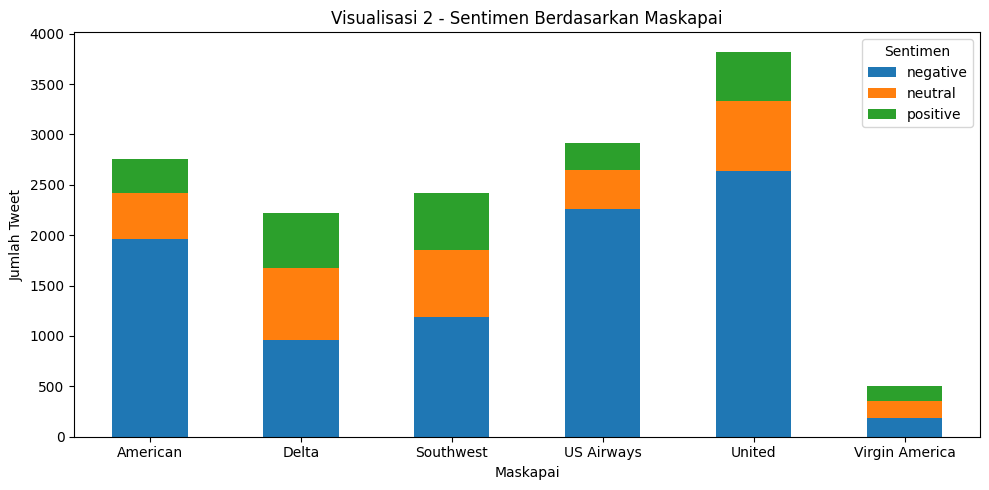

In [ ]:
ct=pd.crosstab(data["airline"],data["airline_sentiment"]).reindex(columns=order,fill_value=0)
ct.plot(kind="bar",stacked=True,figsize=(10,5))
plt.title("Visualisasi 2 - Sentimen Berdasarkan Maskapai")
plt.xlabel("Maskapai"); plt.ylabel("Jumlah Tweet"); plt.xticks(rotation=0)
plt.legend(title="Sentimen"); plt.tight_layout(); plt.show()

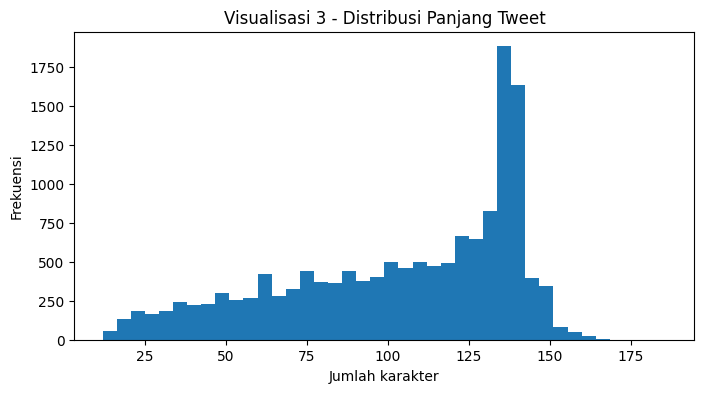

In [ ]:
plt.figure(figsize=(8,4))
plt.hist(data["text_length"],bins=40)
plt.title("Visualisasi 3 - Distribusi Panjang Tweet")
plt.xlabel("Jumlah karakter"); plt.ylabel("Frekuensi"); plt.show()

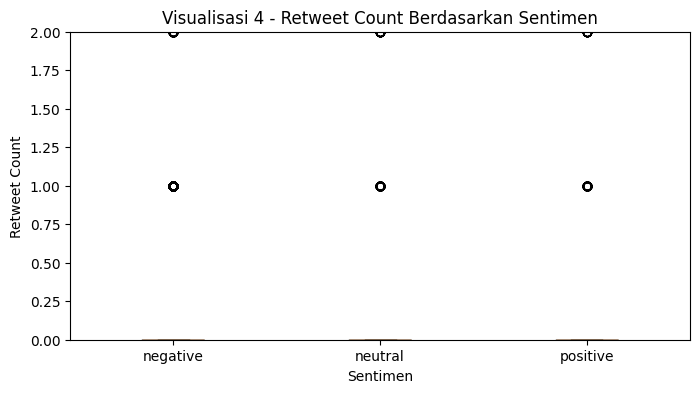

In [ ]:
groups=[data.loc[data["airline_sentiment"]==x,"retweet_count"] for x in order]
plt.figure(figsize=(8,4))
plt.boxplot(groups,labels=order)
plt.ylim(0,data["retweet_count"].quantile(.99)+1)
plt.title("Visualisasi 4 - Retweet Count Berdasarkan Sentimen")
plt.xlabel("Sentimen"); plt.ylabel("Retweet Count"); plt.show()

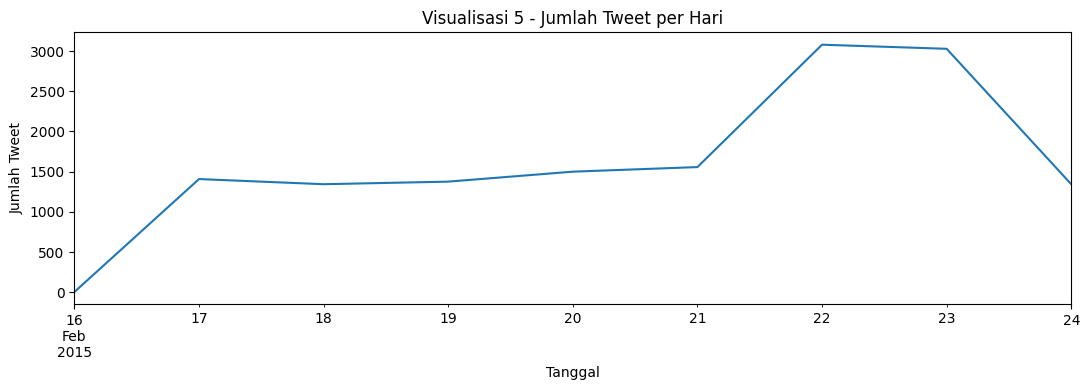

In [ ]:
daily=data.set_index("tweet_created").resample("D").size()
plt.figure(figsize=(11,4)); daily.plot()
plt.title("Visualisasi 5 - Jumlah Tweet per Hari")
plt.xlabel("Tanggal"); plt.ylabel("Jumlah Tweet"); plt.tight_layout(); plt.show()

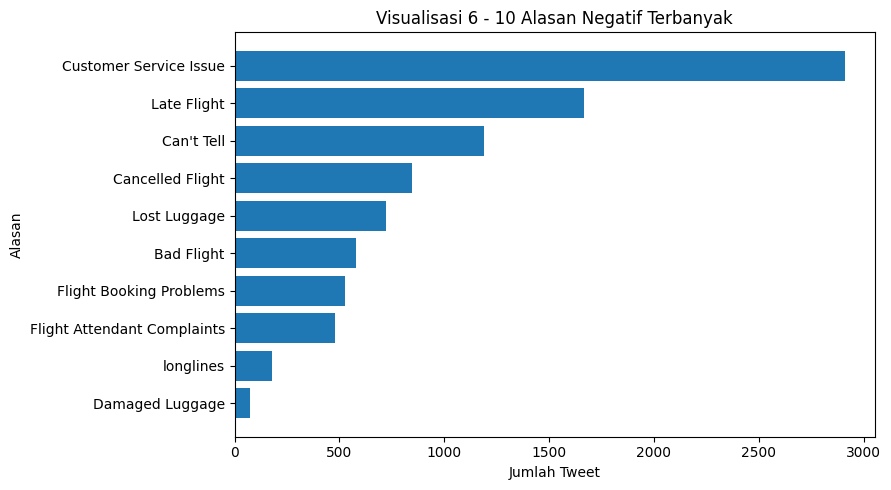

In [ ]:
negative_reason=data.loc[data["airline_sentiment"]=="negative","negativereason"].value_counts().head(10)
plt.figure(figsize=(9,5))
plt.barh(negative_reason.index[::-1],negative_reason.values[::-1])
plt.title("Visualisasi 6 - 10 Alasan Negatif Terbanyak")
plt.xlabel("Jumlah Tweet"); plt.ylabel("Alasan"); plt.tight_layout(); plt.show()

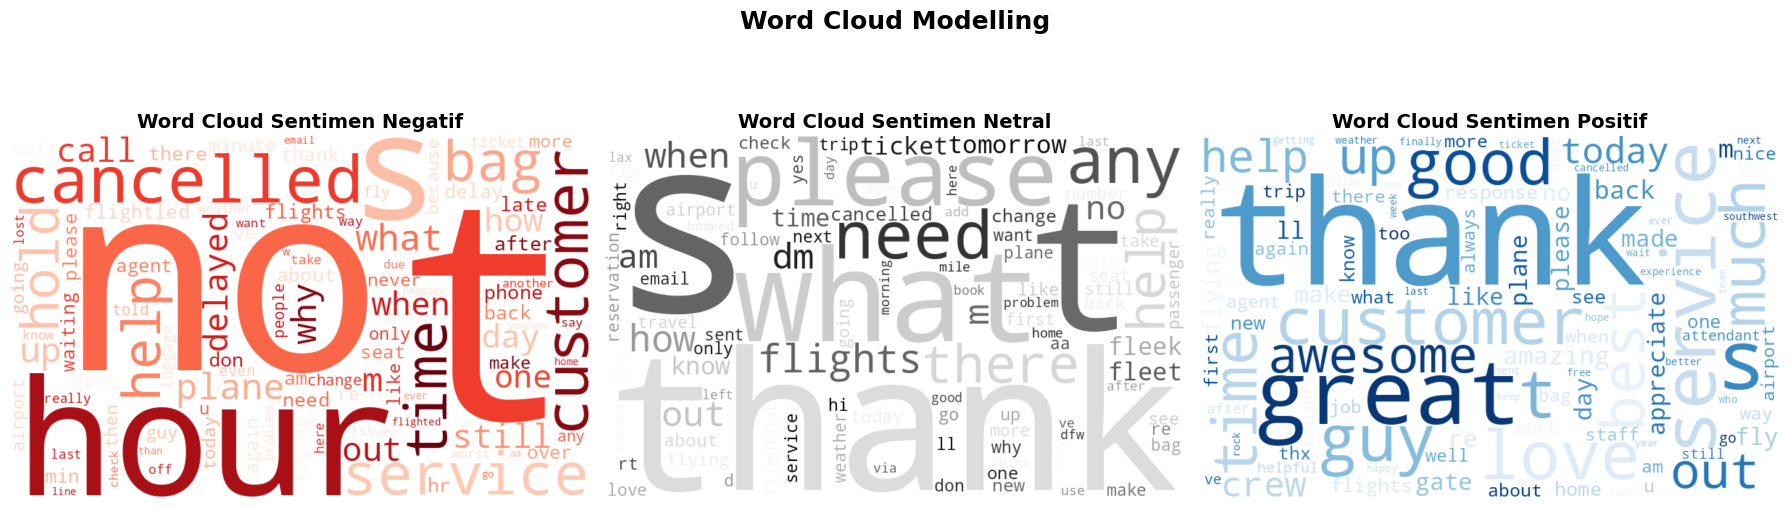

In [ ]:
def clean_text(text):
    text = str(text).lower()

    # Menghapus URL, mention, hashtag, angka, dan tanda baca
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#\w+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Stopwords bahasa Inggris dan kata yang terlalu umum
stopwords = set([
    "the", "a", "an", "and", "or", "but", "if", "of", "to", "in",
    "on", "for", "with", "at", "by", "from", "is", "are", "was",
    "were", "be", "been", "being", "have", "has", "had", "do",
    "does", "did", "will", "would", "could", "should", "can", "may",
    "might", "must", "this", "that", "these", "those", "i", "you",
    "he", "she", "it", "we", "they", "my", "your", "his", "her",
    "our", "their", "me", "him", "us", "them", "as", "not", "so",
    "very", "just", "all", "get", "got", "now", "im", "ive", "id",
    "dont", "didnt", "cant", "wont", "amp",
    "airline", "flight"
])

# Memisahkan teks berdasarkan label sentimen
negative_text = " ".join(
    data.loc[data["airline_sentiment"] == "negative", "text"]
    .dropna()
    .apply(clean_text)
)

neutral_text = " ".join(
    data.loc[data["airline_sentiment"] == "neutral", "text"]
    .dropna()
    .apply(clean_text)
)

positive_text = " ".join(
    data.loc[data["airline_sentiment"] == "positive", "text"]
    .dropna()
    .apply(clean_text)
)

# Membuat Word Cloud
wordcloud_negative = WordCloud(
    width=800, height=500,
    background_color="white",
    stopwords=stopwords,
    max_words=100,
    collocations=False,
    colormap="Reds"
).generate(negative_text)

wordcloud_neutral = WordCloud(
    width=800, height=500,
    background_color="white",
    stopwords=stopwords,
    max_words=100,
    collocations=False,
    colormap="Greys"
).generate(neutral_text)

wordcloud_positive = WordCloud(
    width=800, height=500,
    background_color="white",
    stopwords=stopwords,
    max_words=100,
    collocations=False,
    colormap="Blues"
).generate(positive_text)

# Menampilkan 3 Word Cloud dalam satu gambar
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(wordcloud_negative, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud Sentimen Negatif", fontsize=14, fontweight="bold")

plt.subplot(1, 3, 2)
plt.imshow(wordcloud_neutral, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud Sentimen Netral", fontsize=14, fontweight="bold")

plt.subplot(1, 3, 3)
plt.imshow(wordcloud_positive, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud Sentimen Positif", fontsize=14, fontweight="bold")

plt.suptitle(
    "Word Cloud Modelling",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


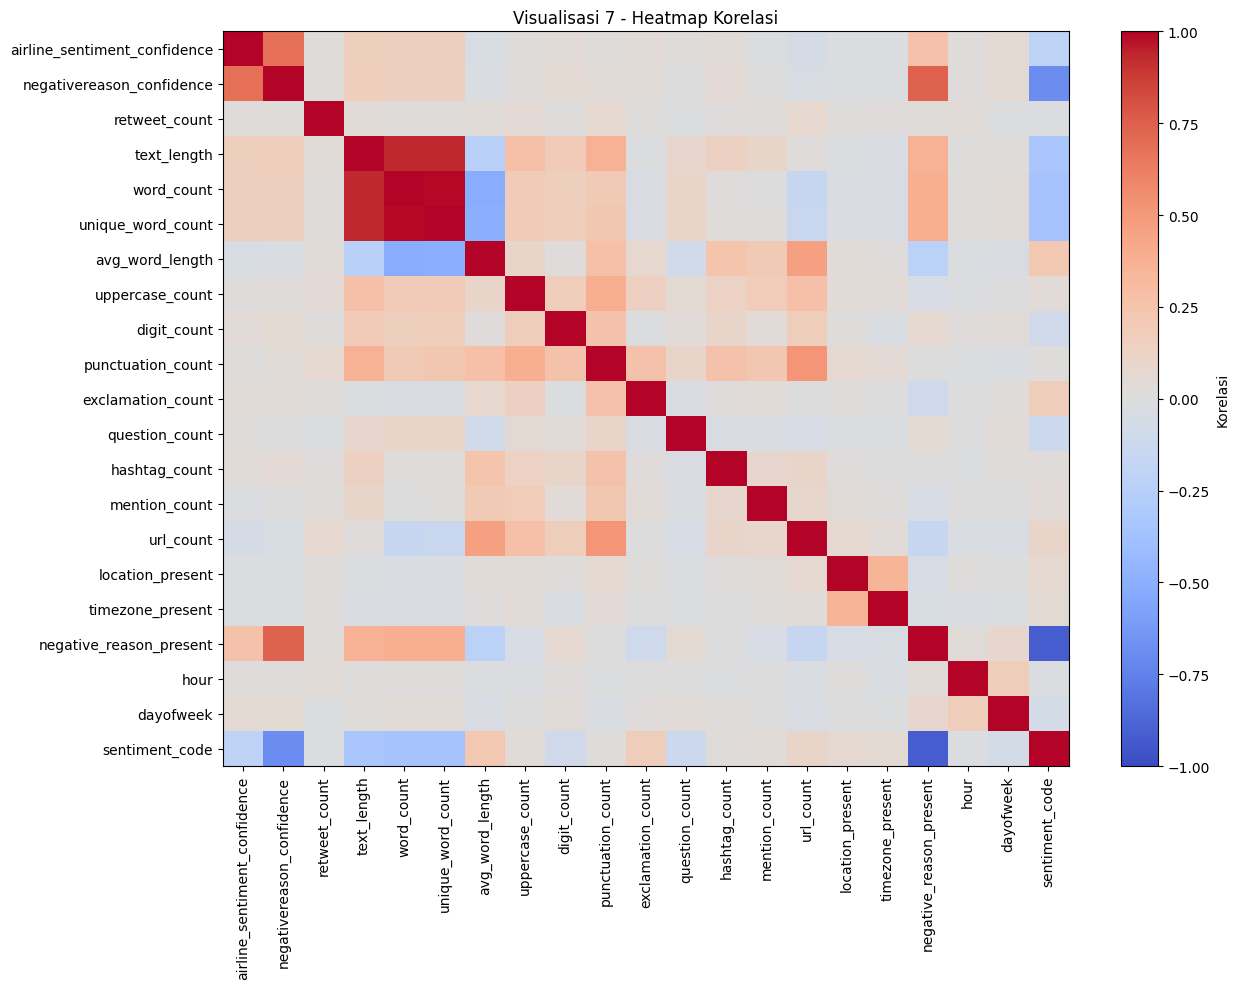

In [ ]:
corr_cols=["airline_sentiment_confidence","negativereason_confidence","retweet_count","text_length","word_count","unique_word_count","avg_word_length","uppercase_count","digit_count","punctuation_count","exclamation_count","question_count","hashtag_count","mention_count","url_count","location_present","timezone_present","negative_reason_present","hour","dayofweek","sentiment_code"]
plt.figure(figsize=(13,10))
plt.imshow(data[corr_cols].corr(),aspect="auto",cmap="coolwarm",vmin=-1,vmax=1)
plt.colorbar(label="Korelasi")
plt.xticks(range(len(corr_cols)),corr_cols,rotation=90)
plt.yticks(range(len(corr_cols)),corr_cols)
plt.title("Visualisasi 7 - Heatmap Korelasi")
plt.tight_layout(); plt.show()

# **5. Correlation Anaysis antara Variabel dan Target**

`airline_sentiment` bersifat kategorikal. Untuk korelasi Pearson eksploratif, target dipetakan menjadi `negative=0`, `neutral=1`, `positive=2`. Encoding ini memberi urutan numerik sehingga hasil korelasi harus ditafsirkan secara hati-hati, bukan sebagai hubungan interval yang sempurna.

,korelasi_dengan_target
negative_reason_present,-0.916402
negativereason_confidence,-0.693294
unique_word_count,-0.358855
word_count,-0.357847
lowercase_count,-0.349119
text_length,-0.335848
avg_word_length,0.212031
airline_sentiment_confidence,-0.205936
exclamation_count,0.178274
question_count,-0.119638


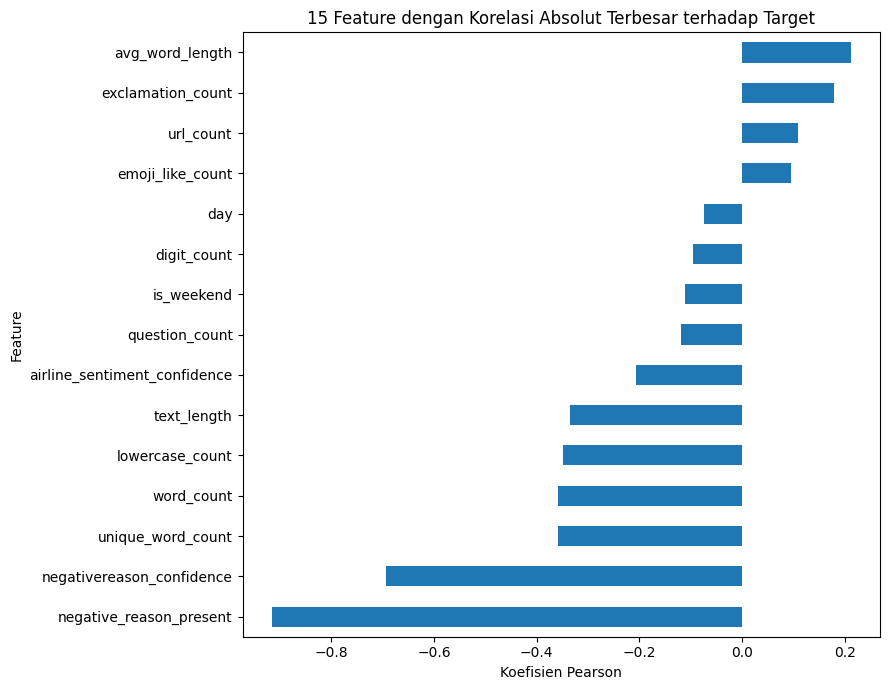

In [ ]:
corr_target=(data[engineered_features+["sentiment_code"]].corr(numeric_only=True)["sentiment_code"]
              .drop("sentiment_code").sort_values(key=np.abs,ascending=False))
display(corr_target.to_frame("korelasi_dengan_target"))
plt.figure(figsize=(9,7))
corr_target.head(15).sort_values().plot(kind="barh")
plt.title("15 Feature dengan Korelasi Absolut Terbesar terhadap Target")
plt.xlabel("Koefisien Pearson"); plt.ylabel("Feature"); plt.tight_layout(); plt.show()


## **6. Klasifikasi Sentimen: TF-IDF + Logistic Regression**

Teks tweet digunakan sebagai input utama. Kolom yang berisi informasi hasil pelabelan seperti `negativereason` dan confidence label tidak dimasukkan ke model agar mengurangi risiko data leakage.

In [ ]:
X=data["text"].fillna("")
y=data["airline_sentiment"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42,stratify=y)
tfidf=TfidfVectorizer(stop_words="english",max_features=20000,ngram_range=(1,2),min_df=2)
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)
model=LogisticRegression(max_iter=1000,random_state=42)
model.fit(X_train_tfidf,y_train)
y_pred=model.predict(X_test_tfidf)
print("Akurasi:",round(accuracy_score(y_test,y_pred),4))
print("\nClassification Report:")
print(classification_report(y_test,y_pred,digits=4))

Akurasi: 0.7794

Classification Report:
              precision    recall  f1-score   support

    negative     0.8057    0.9379    0.8668      1835
     neutral     0.6344    0.4645    0.5363       620
    positive     0.8077    0.5772    0.6732       473

    accuracy                         0.7794      2928
   macro avg     0.7493    0.6599    0.6921      2928
weighted avg     0.7697    0.7794    0.7655      2928



## **7. Kesimpulan**

- Dataset memiliki **14.640 data** dengan target `airline_sentiment`.
- Dataset awal memiliki 15 kolom; setelah feature engineering tersedia **29 feature numerik** untuk analisis.
- Terdapat 8 visualisasi yang mencakup distribusi sentimen, maskapai, panjang tweet, retweet, waktu, alasan negatif, dan korelasi.
- Correlation analysis menunjukkan feature numerik yang paling berkaitan secara eksploratif dengan kode target.
- Klasifikasi baseline menggunakan TF-IDF + Logistic Regression menghasilkan akurasi dan classification report pada output notebook.
- Untuk model klasifikasi, feature yang berpotensi membocorkan label tidak digunakan sebagai input.

TUGAS TERBARU

**Persiapan Library dan Dataset**

In [1]:
from google.colab import drive
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.preprocessing import MaxAbsScaler
from sklearn.decomposition import IncrementalPCA
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/PMA/DatasetPMA.csv'
df = pd.read_csv(DATA_PATH)

print('Ukuran dataset:', df.shape)
print('Kolom:', df.columns.tolist())
display(df.head())

Mounted at /content/drive
Ukuran dataset: (14640, 15)
Kolom: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


Dataset berisi **14.640 baris dan 15 kolom**. Target yang digunakan adalah `airline_sentiment`. Karena eksperimen berfokus pada klasifikasi teks, input utama yang dipakai adalah isi tweet pada kolom `text`.

# Pembagian Data Train dan Test

Data dibagi menjadi **80% data training** dan **20% data testing**. `stratify=y` digunakan agar proporsi tiga kelas sentimen tetap terjaga pada data training dan testing.

`random_state=42` digunakan agar pembagian data dapat direproduksi.

In [3]:
from sklearn.model_selection import train_test_split

# Menentukan fitur berupa teks tweet
X_text = df['text'].fillna('').astype(str)

# Menentukan target
y = df['airline_sentiment']

# Membagi data menjadi training dan testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Jumlah data keseluruhan :", len(df))
print("Jumlah data training    :", len(X_train_text))
print("Jumlah data testing     :", len(X_test_text))

# Menampilkan distribusi kelas pada data training
print("\nDistribusi kelas pada data training:")
print(y_train.value_counts())

# Menampilkan distribusi kelas pada data testing
print("\nDistribusi kelas pada data testing:")
print(y_test.value_counts())

Jumlah data keseluruhan : 14640
Jumlah data training    : 11712
Jumlah data testing     : 2928

Distribusi kelas pada data training:
airline_sentiment
negative    7343
neutral     2479
positive    1890
Name: count, dtype: int64

Distribusi kelas pada data testing:
airline_sentiment
negative    1835
neutral      620
positive     473
Name: count, dtype: int64


Data training berjumlah **11.712 tweet**, sedangkan data testing berjumlah **2.928 tweet**. Pembagian dilakukan secara stratified sehingga distribusi kelas tetap representatif.

Mengubah teks menjadi TF-IDF

# Representasi Teks dengan TF-IDF

Teks diubah menjadi matriks numerik menggunakan **TF-IDF**. Parameter yang digunakan:

- `max_features=20000` → maksimal 20.000 fitur.
- `ngram_range=(1,2)` → menggunakan unigram dan bigram.
- `min_df=2` → fitur yang hanya muncul sekali diabaikan.

Hal penting: **TF-IDF hanya di-fit pada data training**, kemudian data testing hanya ditransformasi. Ini mencegah informasi dari data test masuk ke proses pembentukan fitur.

In [4]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)

X_train: (11712, 20000)
X_test : (2928, 20000)


Matriks training berukuran **(11.712, 20.000)** dan testing **(2.928, 20.000)**. Artinya setiap tweet direpresentasikan menggunakan maksimal 20.000 fitur TF-IDF.

Eksperimen 1 — **Baseline**

Baseline digunakan sebagai titik pembanding. Pada tahap ini tidak dilakukan normalisasi, PCA, regularisasi tambahan, maupun feature selection.

Ketiga algoritma diuji dengan representasi TF-IDF yang sama:

- Logistic Regression
- Linear SVM
- Multinomial Naive Bayes

In [5]:
models_baseline = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42),
    'Naive Bayes': MultinomialNB()
}

results_baseline = []

for name, model in models_baseline.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results_baseline.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

baseline_df = pd.DataFrame(results_baseline)
display(baseline_df)

,Model,Accuracy,Precision,Recall,Macro-F1
0,Logistic Regression,0.801913,0.793722,0.680807,0.720267
1,Linear SVM,0.804303,0.767138,0.716804,0.737788
2,Naive Bayes,0.713456,0.793275,0.495130,0.526267


### Hasil baseline

| Model | Accuracy | Precision | Recall | Macro-F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8019 | 0.7937 | 0.6808 | 0.7203 |
| Linear SVM | 0.8043 | 0.7671 | 0.7168 | 0.7378 |
| Naive Bayes | 0.7135 | 0.7933 | 0.4951 | 0.5263 |

**Result:** Logistic Regression dan Linear SVM menghasilkan performa yang lebih tinggi daripada Naive Bayes pada baseline. Hasil ini menjadi titik acuan untuk eksperimen berikutnya; belum ada model yang dinyatakan sebagai model akhir.

# Eksperimen 2 — Normalisasi

Matriks TF-IDF bersifat sparse. Karena itu digunakan `MaxAbsScaler`, yang mempertahankan struktur sparse dan menskalakan setiap fitur berdasarkan nilai absolut maksimumnya.

Normalisasi dilakukan dengan `fit` pada training dan `transform` pada testing.

In [6]:
scaler = MaxAbsScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

print('Sebelum normalisasi:', X_train.shape, X_test.shape)
print('Sesudah normalisasi :', X_train_norm.shape, X_test_norm.shape)

Sebelum normalisasi: (11712, 20000) (2928, 20000)
Sesudah normalisasi : (11712, 20000) (2928, 20000)


In [7]:
models_norm = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42),
    'Naive Bayes': MultinomialNB()
}

results_norm = []

for name, model in models_norm.items():
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)

    results_norm.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

norm_df = pd.DataFrame(results_norm)
display(norm_df)

,Model,Accuracy,Precision,Recall,Macro-F1
0,Logistic Regression,0.802937,0.766981,0.707520,0.731356
1,Linear SVM,0.773566,0.721797,0.697630,0.708021
2,Naive Bayes,0.789959,0.751192,0.681728,0.708482


### Hasil normalisasi

| Model | Baseline Macro-F1 | Normalisasi Macro-F1 | Perubahan |
|---|---:|---:|---:|
| Logistic Regression | 0.7203 | 0.7314 | +0.0111 |
| Linear SVM | 0.7378 | 0.7080 | -0.0298 |
| Naive Bayes | 0.5263 | 0.7085 | +0.1822 |

**Kejadian:** pengaruh normalisasi tidak sama untuk semua algoritma. Logistic Regression meningkat sedikit, Linear SVM menurun, sedangkan Naive Bayes meningkat cukup besar. Matriks tetap memiliki 20.000 fitur.

# Eksperimen 3 — PCA

PCA digunakan untuk mengurangi jumlah dimensi data hasil normalisasi. Tiga jumlah komponen diuji: **100, 300, dan 500**.

### Catatan teknis Naive Bayes

PCA dapat menghasilkan nilai negatif. Hal ini bermasalah untuk `MultinomialNB`, karena model tersebut mengasumsikan fitur non-negatif. Pada percobaan awal, output PCA digeser agar non-negatif, tetapi model kemudian menghasilkan prediksi yang runtuh menjadi satu kelas (`negative`) sehingga hasil tersebut tidak digunakan sebagai hasil utama.

Untuk PCA, **GaussianNB** digunakan pada eksperimen Naive Bayes karena GaussianNB dapat menangani fitur kontinu yang bernilai negatif. Hasil GaussianNB yang sudah dihitung tersedia untuk PCA 500.

In [10]:
import numpy as np
from sklearn.decomposition import IncrementalPCA

pca_components = [100, 300, 500]

pca_results = {}

batch_size = 512

for n_components in pca_components:

    print(f"\nMenjalankan PCA dengan {n_components} komponen...")

    pca = IncrementalPCA(
        n_components=n_components,
        batch_size=batch_size
    )

    # FIT menggunakan data training
    for start in range(0, X_train_norm.shape[0], batch_size):
        end = min(start + batch_size, X_train_norm.shape[0])
        batch = X_train_norm[start:end].toarray()
        pca.partial_fit(batch)

    # Transform training
    train_batches = []

    for start in range(0, X_train_norm.shape[0], batch_size):
        end = min(start + batch_size, X_train_norm.shape[0])
        batch = X_train_norm[start:end].toarray()
        train_batches.append(pca.transform(batch))

    X_train_pca = np.vstack(train_batches)

    # Transform testing
    test_batches = []

    for start in range(0, X_test_norm.shape[0], batch_size):
        end = min(start + batch_size, X_test_norm.shape[0])
        batch = X_test_norm[start:end].toarray()
        test_batches.append(pca.transform(batch))

    X_test_pca = np.vstack(test_batches)

    # Simpan hasil
    pca_results[n_components] = {
        "model": pca,
        "X_train": X_train_pca,
        "X_test": X_test_pca
    }

    print("X_train:", X_train_pca.shape)
    print("X_test :", X_test_pca.shape)

print("\nPCA selesai.")


Menjalankan PCA dengan 100 komponen...
X_train: (11712, 100)
X_test : (2928, 100)

Menjalankan PCA dengan 300 komponen...
X_train: (11712, 300)
X_test : (2928, 300)

Menjalankan PCA dengan 500 komponen...
X_train: (11712, 500)
X_test : (2928, 500)

PCA selesai.


In [13]:
# ============================================================
# EVALUASI PCA DENGAN 3 ALGORITMA
# Logistic Regression, Linear SVM, dan Gaussian Naive Bayes
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

results_pca = []

for n_components in [100, 300, 500]:

    print(f"\n{'='*60}")
    print(f"PCA dengan {n_components} komponen")
    print(f"{'='*60}")

    # Mengambil data PCA
    X_train_pca_current = pca_results[n_components]["X_train"]
    X_test_pca_current = pca_results[n_components]["X_test"]

    # --------------------------------------------------------
    # 1. Logistic Regression
    # --------------------------------------------------------
    lr = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    lr.fit(X_train_pca_current, y_train)
    y_pred_lr = lr.predict(X_test_pca_current)

    results_pca.append({
        "Komponen": n_components,
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(
            y_test, y_pred_lr,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_lr,
            average="macro",
            zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, y_pred_lr,
            average="macro",
            zero_division=0
        )
    })

    # --------------------------------------------------------
    # 2. Linear SVM
    # --------------------------------------------------------
    svm = LinearSVC(
        max_iter=5000,
        random_state=42
    )

    svm.fit(X_train_pca_current, y_train)
    y_pred_svm = svm.predict(X_test_pca_current)

    results_pca.append({
        "Komponen": n_components,
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "Precision": precision_score(
            y_test, y_pred_svm,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_svm,
            average="macro",
            zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, y_pred_svm,
            average="macro",
            zero_division=0
        )
    })

    # --------------------------------------------------------
    # 3. Gaussian Naive Bayes
    # --------------------------------------------------------
    # GaussianNB digunakan karena fitur PCA bersifat kontinu
    # dan dapat memiliki nilai negatif.

    nb = GaussianNB()

    nb.fit(X_train_pca_current, y_train)
    y_pred_nb = nb.predict(X_test_pca_current)

    results_pca.append({
        "Komponen": n_components,
        "Model": "Gaussian Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "Precision": precision_score(
            y_test, y_pred_nb,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_nb,
            average="macro",
            zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, y_pred_nb,
            average="macro",
            zero_division=0
        )
    })

# Membuat tabel hasil
pca_df = pd.DataFrame(results_pca)

# Menampilkan hasil
display(
    pca_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro-F1": "{:.4f}"
    })
)


PCA dengan 100 komponen

PCA dengan 300 komponen

PCA dengan 500 komponen


,Komponen,Model,Accuracy,Precision,Recall,Macro-F1
0,100,Logistic Regression,0.7544,0.7109,0.6276,0.6571
1,100,Linear SVM,0.7507,0.7141,0.6128,0.6459
2,100,Gaussian Naive Bayes,0.5639,0.5077,0.5104,0.4735
3,300,Logistic Regression,0.7766,0.7366,0.6651,0.6925
4,300,Linear SVM,0.7773,0.7410,0.6609,0.6907
5,300,Gaussian Naive Bayes,0.4816,0.4822,0.4978,0.4263
6,500,Logistic Regression,0.7852,0.7405,0.6762,0.7015
7,500,Linear SVM,0.7859,0.7419,0.6781,0.7033
8,500,Gaussian Naive Bayes,0.4071,0.4535,0.4731,0.3787


### Hasil PCA yang diperoleh

| Komponen | Model | Accuracy | Precision | Recall | Macro-F1 |
|---:|---|---:|---:|---:|---:|
| 100 | Logistic Regression | 0.7503 | 0.7024 | 0.6209 | 0.6494 |
| 100 | Linear SVM | 0.7490 | 0.7129 | 0.6105 | 0.6437 |
| 300 | Logistic Regression | 0.7756 | 0.7360 | 0.6612 | 0.6895 |
| 300 | Linear SVM | 0.7753 | 0.7386 | 0.6595 | 0.6890 |
| 500 | Logistic Regression | 0.7883 | 0.7438 | 0.6801 | 0.7053 |
| 500 | Linear SVM | 0.7859 | 0.7397 | 0.6776 | 0.7022 |
| 500 | Gaussian Naive Bayes | 0.4071 | 0.4557 | 0.4782 | 0.3817 |

**Kejadian penting:** semakin banyak komponen dari 100 → 300 → 500, performa Logistic Regression dan SVM meningkat. Namun pada 500 komponen, Macro-F1 keduanya masih di bawah hasil normalisasi tanpa PCA. Untuk Naive Bayes, perubahan ke GaussianNB menghasilkan performa yang jauh berbeda dari MultinomialNB pada tahap sebelumnya, sehingga perbandingan harus dibaca dengan mempertimbangkan perbedaan jenis model.

# Eksperimen 4 — Regularisasi

Regularisasi dilakukan pada data yang sudah dinormalisasi. Tujuannya melihat bagaimana perubahan parameter model memengaruhi performa.

- Logistic Regression → parameter `C`
- Linear SVM → parameter `C`
- Naive Bayes → parameter `alpha` (smoothing)

In [14]:
# Logistic Regression
C_values = [0.01, 0.1, 1, 10, 100]
lr_reg_results = []

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)

    lr_reg_results.append({
        'C': c,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

lr_reg_df = pd.DataFrame(lr_reg_results)
display(lr_reg_df)

,C,Accuracy,Precision,Recall,Macro-F1
0,0.01,0.673156,0.762544,0.423066,0.422410
1,0.10,0.790301,0.790997,0.652763,0.696084
2,1.00,0.802937,0.766981,0.707520,0.731356
3,10.00,0.786885,0.739681,0.702644,0.718038
4,100.00,0.785861,0.732375,0.705760,0.717267


### Hasil Logistic Regression

Macro-F1 untuk C = 0,01; 0,1; 1; 10; 100 berturut-turut adalah **0,4224; 0,6961; 0,7314; 0,7180; 0,7173**.

**Kejadian:** performa meningkat sampai C=1, kemudian sedikit menurun ketika C diperbesar menjadi 10 dan 100. Pada rentang pengujian ini, C=1 menghasilkan Macro-F1 tertinggi untuk Logistic Regression.

Regularisasi Linear SVM

uji nilai C:

0.01, 0.1, 1, 10, 100

In [15]:
# Linear SVM
svm_reg_results = []

for c in C_values:
    model = LinearSVC(C=c, max_iter=5000, random_state=42)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)

    svm_reg_results.append({
        'C': c,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

svm_reg_df = pd.DataFrame(svm_reg_results)
display(svm_reg_df)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,C,Accuracy,Precision,Recall,Macro-F1
0,0.01,0.773224,0.796131,0.616379,0.664497
1,0.10,0.803962,0.767553,0.713463,0.735870
2,1.00,0.773566,0.721797,0.697630,0.708021
3,10.00,0.756148,0.692419,0.679386,0.684918
4,100.00,0.749658,0.677471,0.672186,0.674597


### Hasil Linear SVM

| C | Accuracy | Precision | Recall | Macro-F1 |
|---:|---:|---:|---:|---:|
| 0.01 | 0.7732 | 0.7961 | 0.6164 | 0.6645 |
| 0.10 | 0.8040 | 0.7676 | 0.7135 | 0.7359 |
| 1 | 0.7736 | 0.7218 | 0.6976 | 0.7080 |
| 10 | 0.7561 | 0.6924 | 0.6794 | 0.6849 |
| 100 | 0.7497 | 0.6775 | 0.6722 | 0.6746 |

**Kejadian:** pada percobaan awal muncul peringatan `Liblinear failed to converge`. Eksperimen kemudian diulang dengan `max_iter=5000`. Nilai hasil utama di atas berasal dari percobaan tersebut. C=0,10 menghasilkan Macro-F1 tertinggi pada rentang parameter yang diuji.

In [16]:
# Naive Bayes
alpha_values = [0.01, 0.1, 1, 10, 100]
nb_reg_results = []

for alpha in alpha_values:
    model = MultinomialNB(alpha=alpha)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)

    nb_reg_results.append({
        'Alpha': alpha,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

nb_reg_df = pd.DataFrame(nb_reg_results)
display(nb_reg_df)

,Alpha,Accuracy,Precision,Recall,Macro-F1
0,0.01,0.775273,0.722462,0.661843,0.685389
1,0.10,0.787910,0.729157,0.701568,0.713636
2,1.00,0.789959,0.751192,0.681728,0.708482
3,10.00,0.676230,0.775426,0.425958,0.426554
4,100.00,0.633538,0.712100,0.345822,0.283312


### Hasil Naive Bayes

| Alpha | Accuracy | Precision | Recall | Macro-F1 |
|---:|---:|---:|---:|---:|
| 0.01 | 0.7753 | 0.7225 | 0.6618 | 0.6854 |
| 0.10 | 0.7879 | 0.7292 | 0.7016 | 0.7136 |
| 1 | 0.7900 | 0.7512 | 0.6817 | 0.7085 |
| 10 | 0.6762 | 0.7754 | 0.4260 | 0.4266 |
| 100 | 0.6335 | 0.7121 | 0.3458 | 0.2833 |

**Result:** nilai alpha yang terlalu besar menyebabkan Macro-F1 turun tajam. Pada rentang pengujian, alpha=0,10 menghasilkan Macro-F1 tertinggi.

# Eksperimen 5 — Feature Selection

Feature selection dilakukan menggunakan `SelectKBest` dengan skor **chi-square (`chi2`)**. Data yang digunakan adalah data hasil normalisasi.

Jumlah fitur yang diuji:

- 1.000 fitur
- 3.000 fitur
- 5.000 fitur
- 10.000 fitur

Ketiga algoritma tetap diuji pada setiap jumlah fitur.

In [17]:
k_values = [1000, 3000, 5000, 10000]
fs_results = []

for k in k_values:
    selector = SelectKBest(score_func=chi2, k=k)
    X_train_fs = selector.fit_transform(X_train_norm, y_train)
    X_test_fs = selector.transform(X_test_norm)

    models_fs = {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Linear SVM': LinearSVC(max_iter=5000, random_state=42),
        'Naive Bayes': MultinomialNB()
    }

    for name, model in models_fs.items():
        model.fit(X_train_fs, y_train)
        y_pred = model.predict(X_test_fs)

        fs_results.append({
            'k': k,
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
            'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
            'Macro-F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
        })

fs_df = pd.DataFrame(fs_results)
display(fs_df)

,k,Model,Accuracy,Precision,Recall,Macro-F1
0,1000,Logistic Regression,0.784153,0.750785,0.679897,0.707617
1,1000,Linear SVM,0.779030,0.741106,0.678218,0.703374
2,1000,Naive Bayes,0.751025,0.723724,0.613268,0.646436
3,3000,Logistic Regression,0.798839,0.762396,0.702216,0.726785
4,3000,Linear SVM,0.788251,0.742487,0.694216,0.714501
5,3000,Naive Bayes,0.780738,0.759015,0.659170,0.691749
6,5000,Logistic Regression,0.800888,0.762889,0.702303,0.726918
7,5000,Linear SVM,0.783128,0.737194,0.690533,0.710141
8,5000,Naive Bayes,0.778005,0.740048,0.662221,0.689863
9,10000,Logistic Regression,0.799522,0.762225,0.701642,0.725883


penggunaan hanya 1.000 fitur menurunkan performa ketiga algoritma dibandingkan jumlah fitur yang lebih besar. Performa kemudian cenderung stabil pada jumlah fitur 3.000–10.000. Nilai jumlah fitur yang memberikan Macro-F1 tertinggi berbeda antaralgoritma.

# Tabel Rekap Seluruh Eksperimen

In [18]:
# Rekap berdasarkan hasil eksperimen yang telah diperoleh

rekap = pd.DataFrame([
    ['Baseline','Logistic Regression','-',0.801913,0.793722,0.680807,0.720267],
    ['Baseline','Linear SVM','-',0.804303,0.767138,0.716804,0.737788],
    ['Baseline','Naive Bayes','-',0.713456,0.793275,0.495130,0.526267],
    ['Normalisasi','Logistic Regression','MaxAbsScaler',0.802937,0.766981,0.707520,0.731356],
    ['Normalisasi','Linear SVM','MaxAbsScaler',0.773566,0.721797,0.697630,0.708021],
    ['Normalisasi','Naive Bayes','MaxAbsScaler',0.789959,0.751192,0.681728,0.708482],
    ['PCA','Logistic Regression','100 komponen',0.750342,0.702361,0.620918,0.649431],
    ['PCA','Linear SVM','100 komponen',0.748975,0.712934,0.610478,0.643686],
    ['PCA','Logistic Regression','300 komponen',0.775615,0.735990,0.661233,0.689485],
    ['PCA','Linear SVM','300 komponen',0.775273,0.738629,0.659460,0.688965],
    ['PCA','Logistic Regression','500 komponen',0.788251,0.743780,0.680115,0.705291],
    ['PCA','Linear SVM','500 komponen',0.785861,0.739690,0.677565,0.702186],
    ['PCA','Gaussian Naive Bayes','500 komponen',0.407104,0.455713,0.478196,0.381678],
    ['Regularisasi','Logistic Regression','C=0.01',0.673156,0.762544,0.423066,0.422410],
    ['Regularisasi','Logistic Regression','C=0.10',0.790301,0.790997,0.652763,0.696084],
    ['Regularisasi','Logistic Regression','C=1.00',0.802937,0.766981,0.707520,0.731356],
    ['Regularisasi','Logistic Regression','C=10.00',0.786885,0.739681,0.702644,0.718038],
    ['Regularisasi','Logistic Regression','C=100.00',0.785861,0.732375,0.705760,0.717267],
    ['Regularisasi','Linear SVM','C=0.01',0.773224,0.796131,0.616379,0.664497],
    ['Regularisasi','Linear SVM','C=0.10',0.803962,0.767553,0.713463,0.735870],
    ['Regularisasi','Linear SVM','C=1.00',0.773566,0.721797,0.697630,0.708021],
    ['Regularisasi','Linear SVM','C=10.00',0.756148,0.692419,0.679386,0.684918],
    ['Regularisasi','Linear SVM','C=100.00',0.749658,0.677471,0.672186,0.674597],
    ['Regularisasi','Naive Bayes','alpha=0.01',0.775273,0.722462,0.661843,0.685389],
    ['Regularisasi','Naive Bayes','alpha=0.10',0.787910,0.729157,0.701568,0.713636],
    ['Regularisasi','Naive Bayes','alpha=1.00',0.789959,0.751192,0.681728,0.708482],
    ['Regularisasi','Naive Bayes','alpha=10.00',0.676230,0.775426,0.425958,0.426554],
    ['Regularisasi','Naive Bayes','alpha=100.00',0.633538,0.712100,0.345822,0.283312],
], columns=['Eksperimen','Model','Parameter','Accuracy','Precision','Recall','Macro-F1'])

fs_rekap = fs_df.copy()
fs_rekap['Eksperimen'] = 'Feature Selection'
fs_rekap['Parameter'] = 'k=' + fs_rekap['k'].astype(str)
fs_rekap = fs_rekap[['Eksperimen','Model','Parameter','Accuracy','Precision','Recall','Macro-F1']]

rekap = pd.concat([rekap, fs_rekap], ignore_index=True)

display(rekap.round(4))

,Eksperimen,Model,Parameter,Accuracy,Precision,Recall,Macro-F1
0,Baseline,Logistic Regression,-,0.8019,0.7937,0.6808,0.7203
1,Baseline,Linear SVM,-,0.8043,0.7671,0.7168,0.7378
2,Baseline,Naive Bayes,-,0.7135,0.7933,0.4951,0.5263
3,Normalisasi,Logistic Regression,MaxAbsScaler,0.8029,0.7670,0.7075,0.7314
4,Normalisasi,Linear SVM,MaxAbsScaler,0.7736,0.7218,0.6976,0.7080
5,Normalisasi,Naive Bayes,MaxAbsScaler,0.7900,0.7512,0.6817,0.7085
6,PCA,Logistic Regression,100 komponen,0.7503,0.7024,0.6209,0.6494
7,PCA,Linear SVM,100 komponen,0.7490,0.7129,0.6105,0.6437
8,PCA,Logistic Regression,300 komponen,0.7756,0.7360,0.6612,0.6895
9,PCA,Linear SVM,300 komponen,0.7753,0.7386,0.6595,0.6890


# Ringkasan Hasil dan Kejadian Penting

### Baseline
Baseline menunjukkan bahwa Logistic Regression dan Linear SVM memiliki performa yang lebih tinggi daripada Naive Bayes berdasarkan Macro-F1. Baseline menjadi pembanding untuk seluruh eksperimen berikutnya.

### Normalisasi
Normalisasi tidak memberikan dampak yang sama pada setiap model. Logistic Regression meningkat sedikit, Linear SVM menurun, sedangkan Naive Bayes mengalami peningkatan besar.

### PCA
PCA berhasil mengurangi dimensi dari 20.000 fitur menjadi 100, 300, atau 500 komponen. Pada Logistic Regression dan Linear SVM, peningkatan jumlah komponen dari 100 ke 500 diikuti peningkatan Macro-F1. Namun hasil PCA 500 masih berada di bawah hasil normalisasi tanpa PCA. Pada Naive Bayes muncul masalah teknis karena PCA menghasilkan nilai negatif; oleh karena itu GaussianNB digunakan pada PCA 500 dan hasilnya dicatat terpisah.

### Regularisasi
Parameter regularisasi memiliki pengaruh kuat. Pada Logistic Regression, performa terbaik dalam rentang uji terjadi pada C=1. Pada Linear SVM, performa tertinggi terjadi pada C=0,10. Pada Naive Bayes, alpha=0,10 menghasilkan Macro-F1 tertinggi. Pada SVM juga sempat muncul peringatan konvergensi, sehingga `max_iter` dinaikkan menjadi 5000.

### Feature Selection
Feature selection menunjukkan bahwa jumlah fitur yang terlalu sedikit (1.000) cenderung menurunkan performa. Performa kemudian relatif stabil pada 3.000–10.000 fitur, dan jumlah fitur dengan Macro-F1 tertinggi berbeda antaralgoritma.

## Kesimpulan sementara

Eksperimen menunjukkan bahwa **tidak ada satu preprocessing yang memberikan perubahan identik pada semua algoritma**. Pengaruh normalisasi, PCA, regularisasi, dan feature selection bergantung pada karakteristik masing-masing model. Karena itu, seluruh hasil perlu dipertimbangkan secara bersama-sama sebelum menentukan konfigurasi yang akan digunakan pada tahap akhir tugas.